# Figure S3 — retrieval by held-out context, target-gene masking, pooling and knockdown strength (related to Figure 2)

Renders panels A–E from the cached tables in `data/` (written by `figS3_data.py`; `data/figS3d_ood_by_shift_cell.csv` is a copy of Fig. 2's `fig2b_shift.csv`, made by the figS3 sbatch plot step). Styling comes from `fig2_plot.py`. Panels go to `render/`.

In [1]:
import sys
from pathlib import Path
_paper = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'scripts' / 'common').is_dir())
sys.path.insert(0, str(_paper / 'scripts' / 'common'))
import nbtools as nb                      # puts paper/scripts/*/ on sys.path

vs = nb.vizstyle()
DATA, INPUTS, OUT, SRC = nb.folders()     # data/ (cache), inputs/, render/, render/src/

In [2]:
import json
import fig2_common as F
import fig2_plot as P2
import figS3_plot as P

P2.setup(DATA, str(nb.STYLE), palette='figS3_palette.csv')
meta = json.loads((DATA / 'figS3_meta.json').read_text())
metrics = [meta['f1'], F.R10, meta['mrr']]   # F1, top-10 recall, MRR

## A — OOD on held-out conditions, pseudobulk

  wrote figS3a_ood_condition.svg / .png


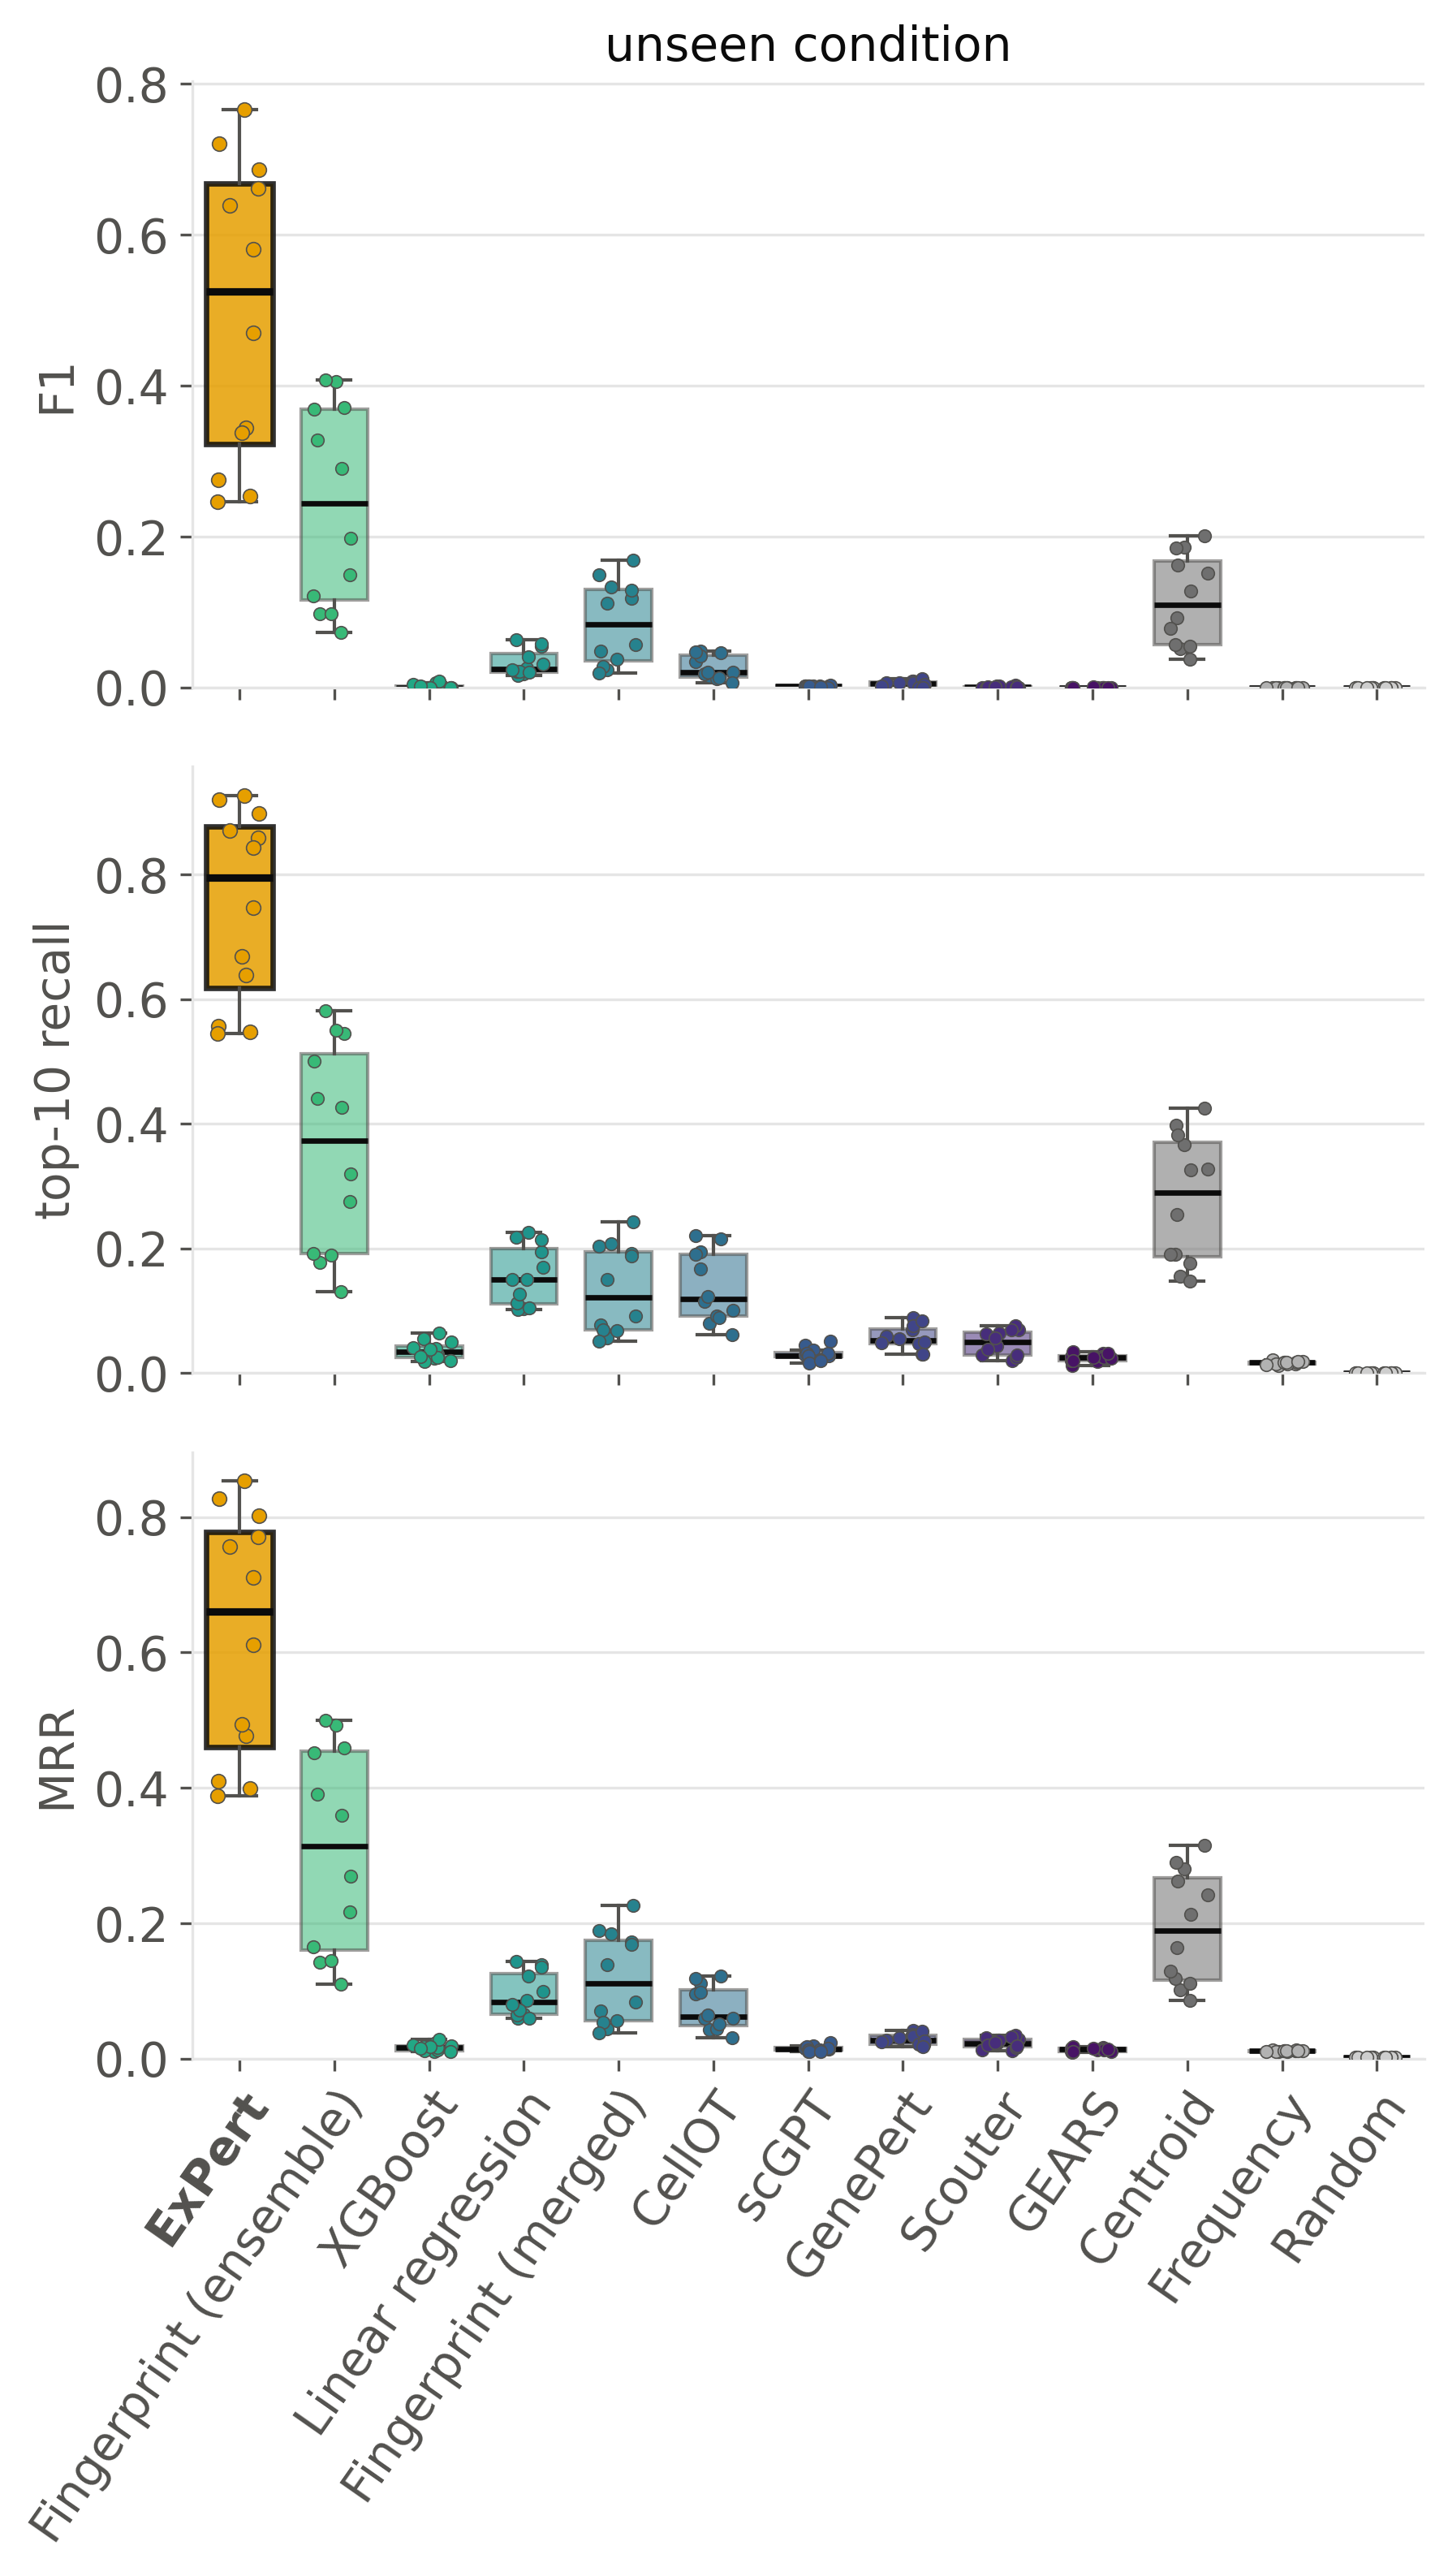

In [3]:
P2.panel_b(DATA, OUT, metrics, keep=('ood_condition',), name='figS3a_ood_condition',
           table='figS3a_ood_condition.csv')
nb.show(OUT, 'figS3a_ood_condition')

## B — per fold, ExPert top-10 recall / best other method, ID and OOD

  wrote figS3b_increase_over_next_best.svg / .png


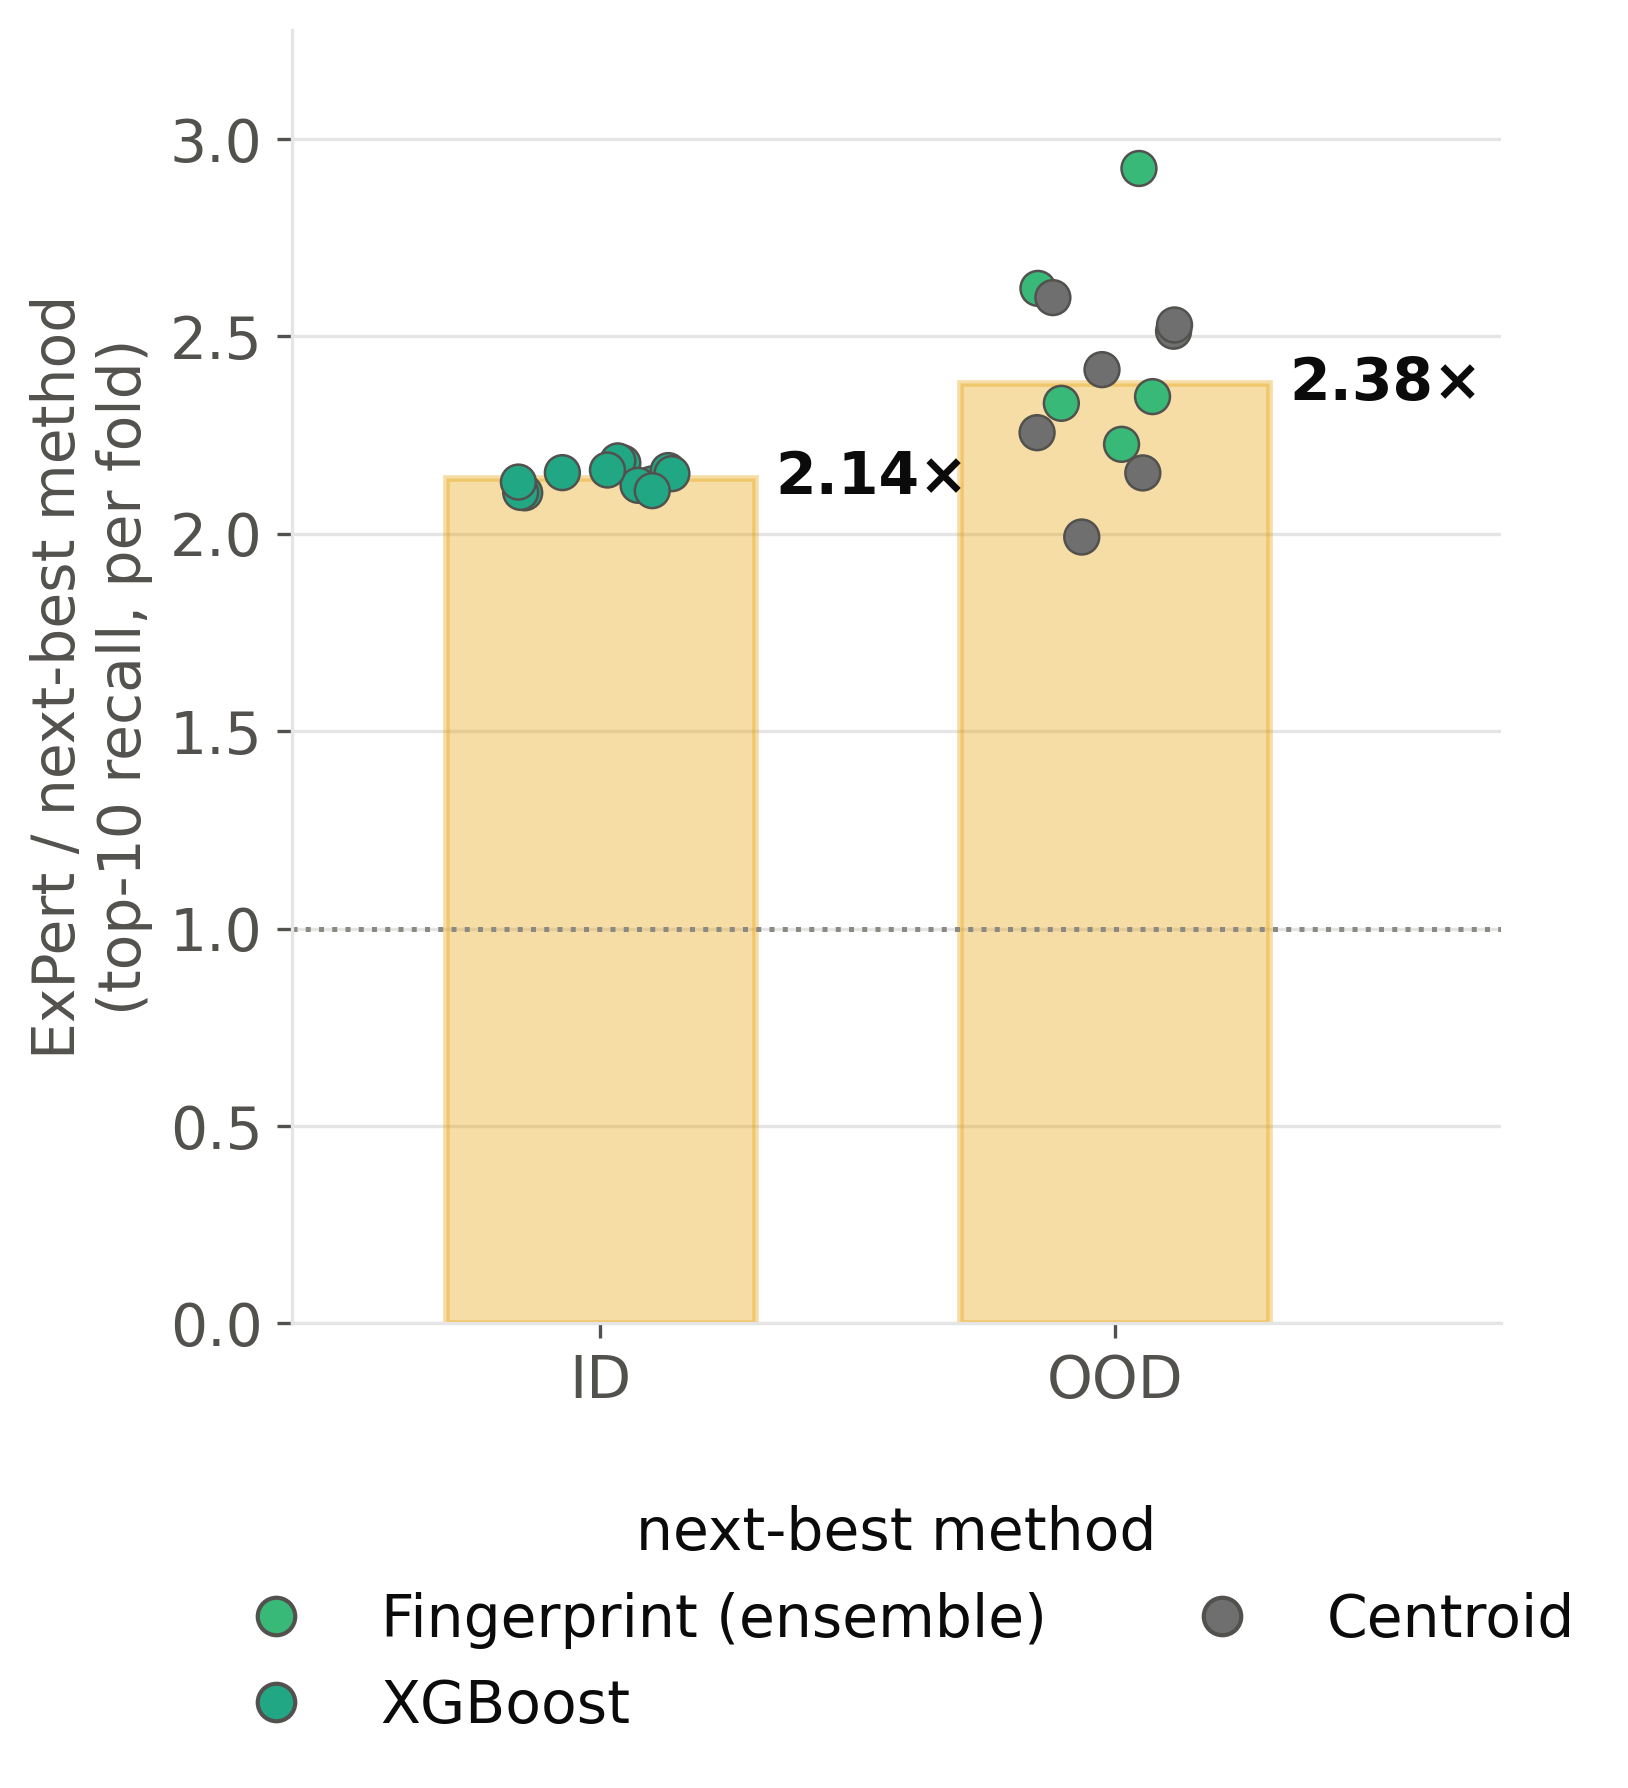

In [4]:
P.headline(DATA, OUT)
nb.show(OUT, 'figS3b_increase_over_next_best')

## C — masking each perturbation's own target gene in the query, pseudobulk

  wrote figS3c_target_mask.svg / .png


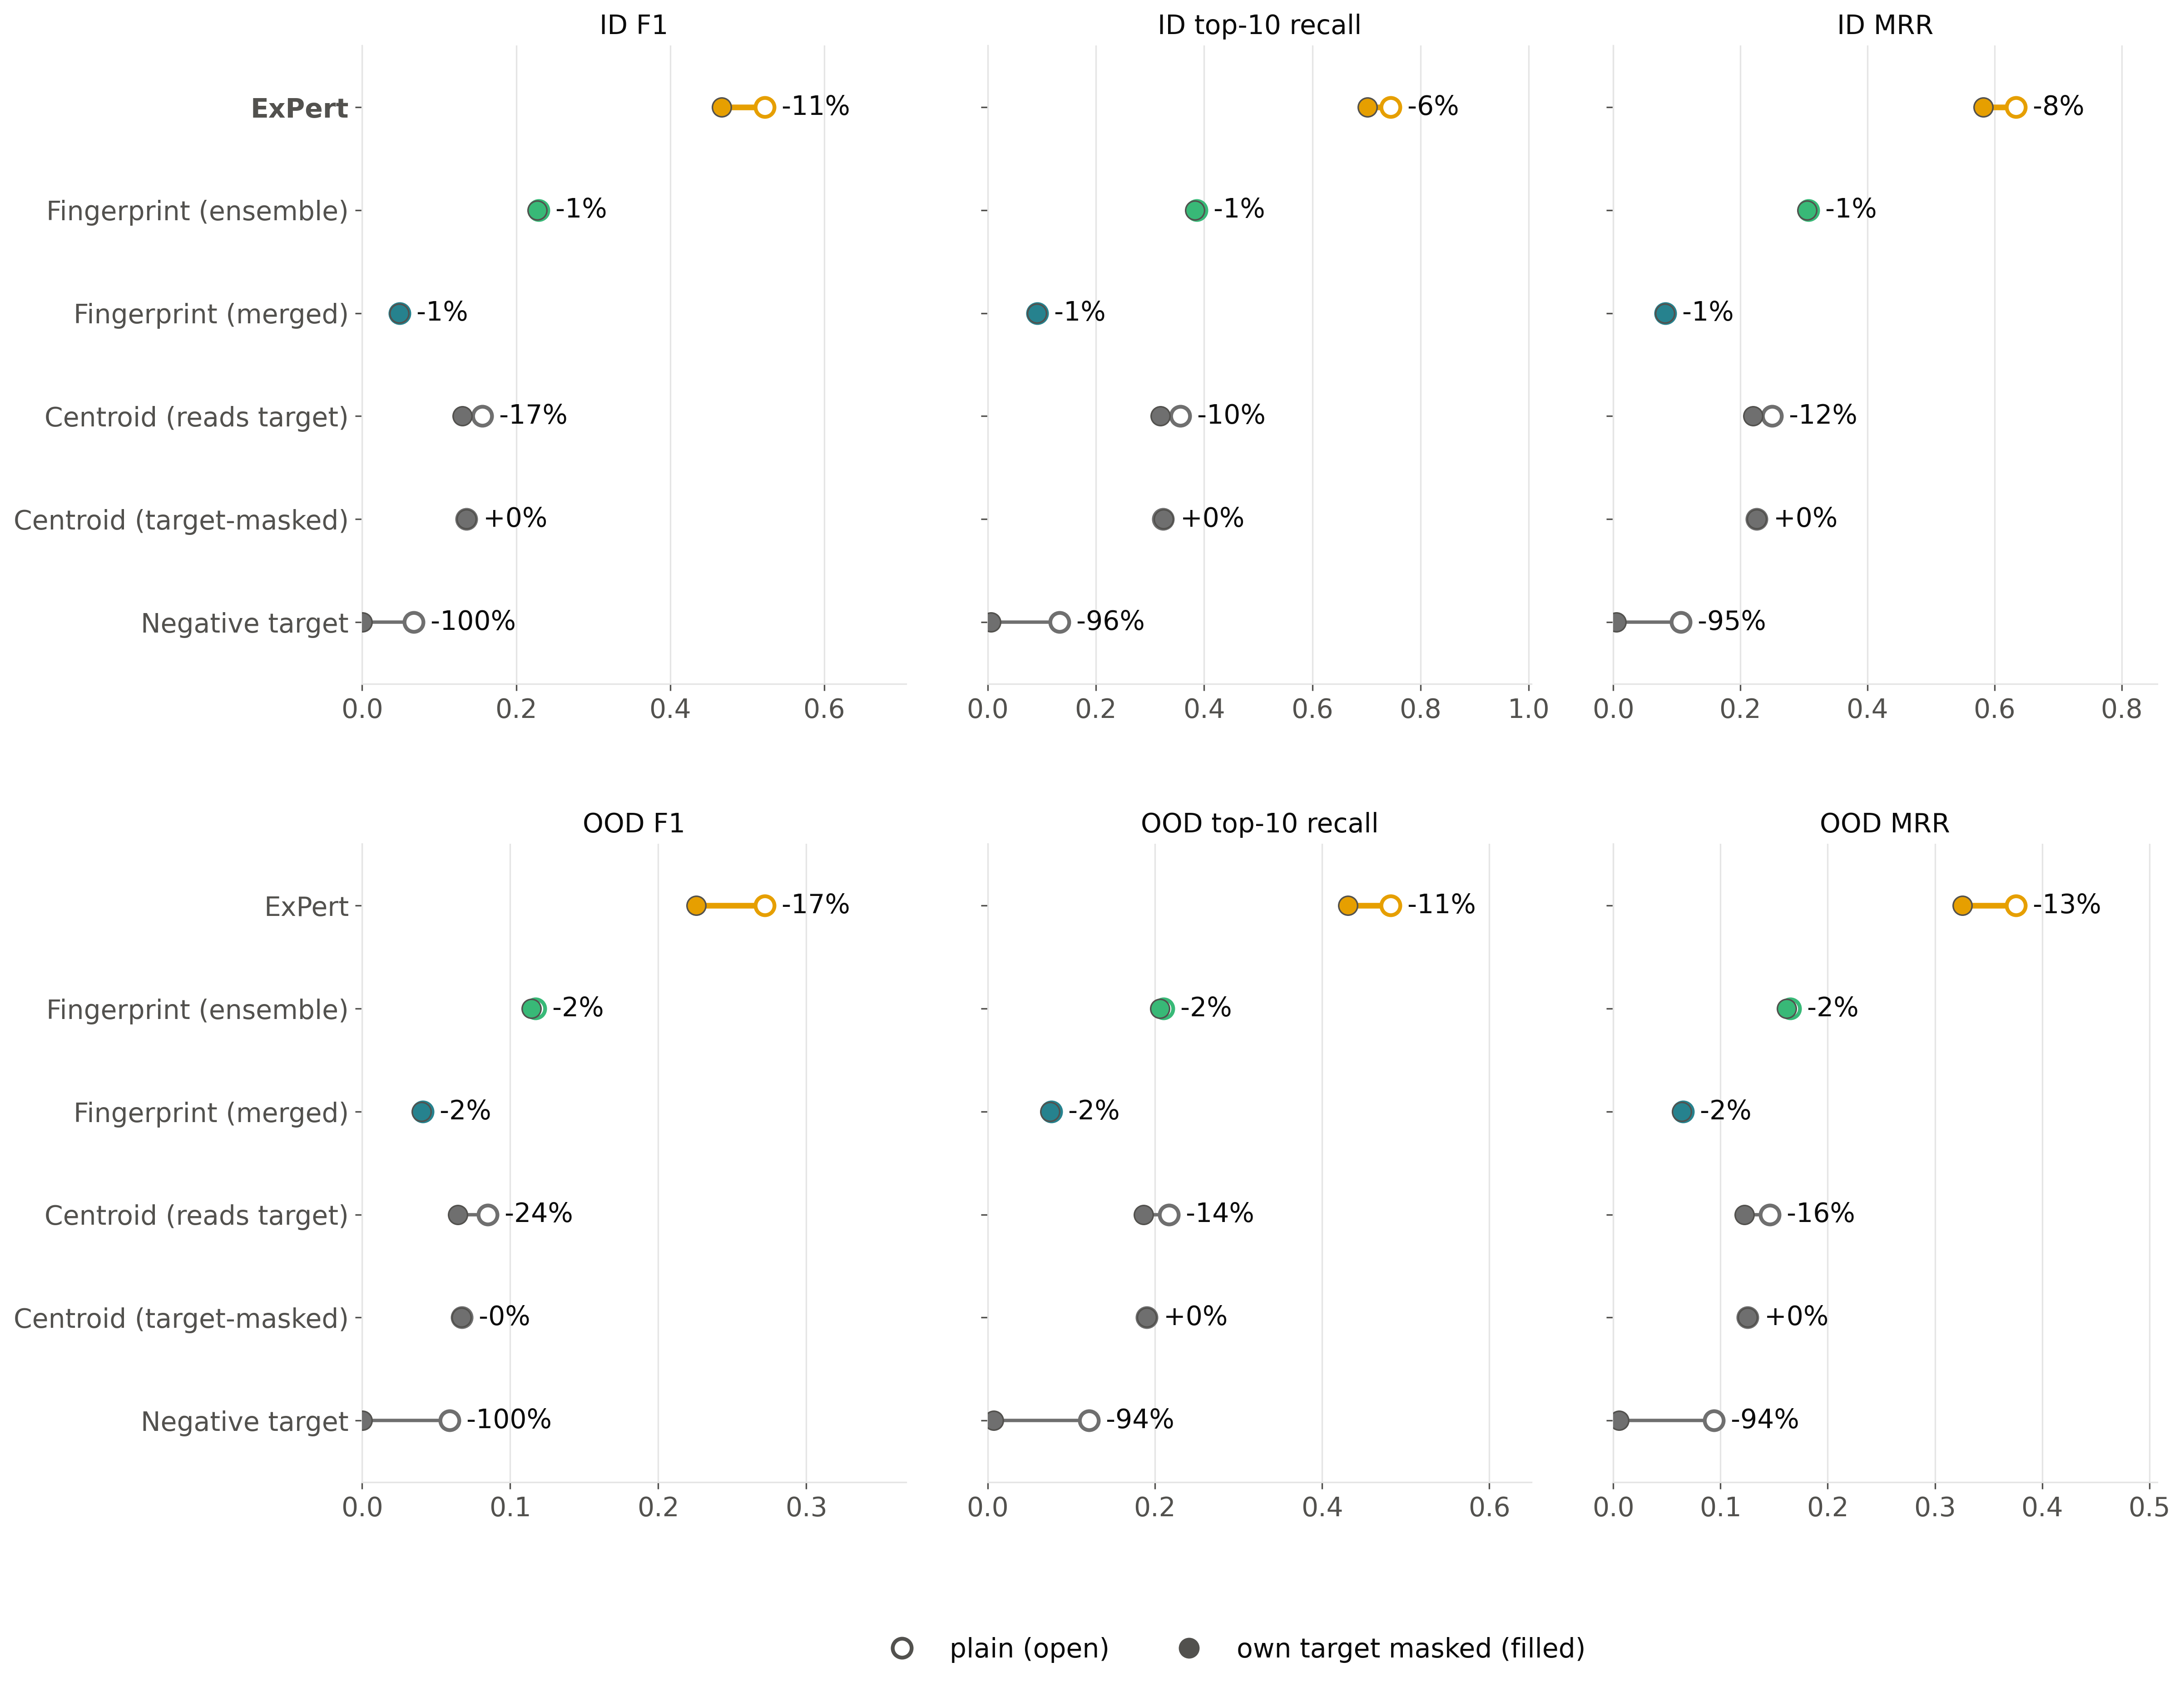

In [5]:
P.target_mask(DATA, OUT, table='figS3c_target_mask.csv', name='figS3c_target_mask')
nb.show(OUT, 'figS3c_target_mask')

## D — Figure 2C on single cells (effect-size weighted), by held-out context

  wrote figS3d_ood_by_shift_cell.svg / .png


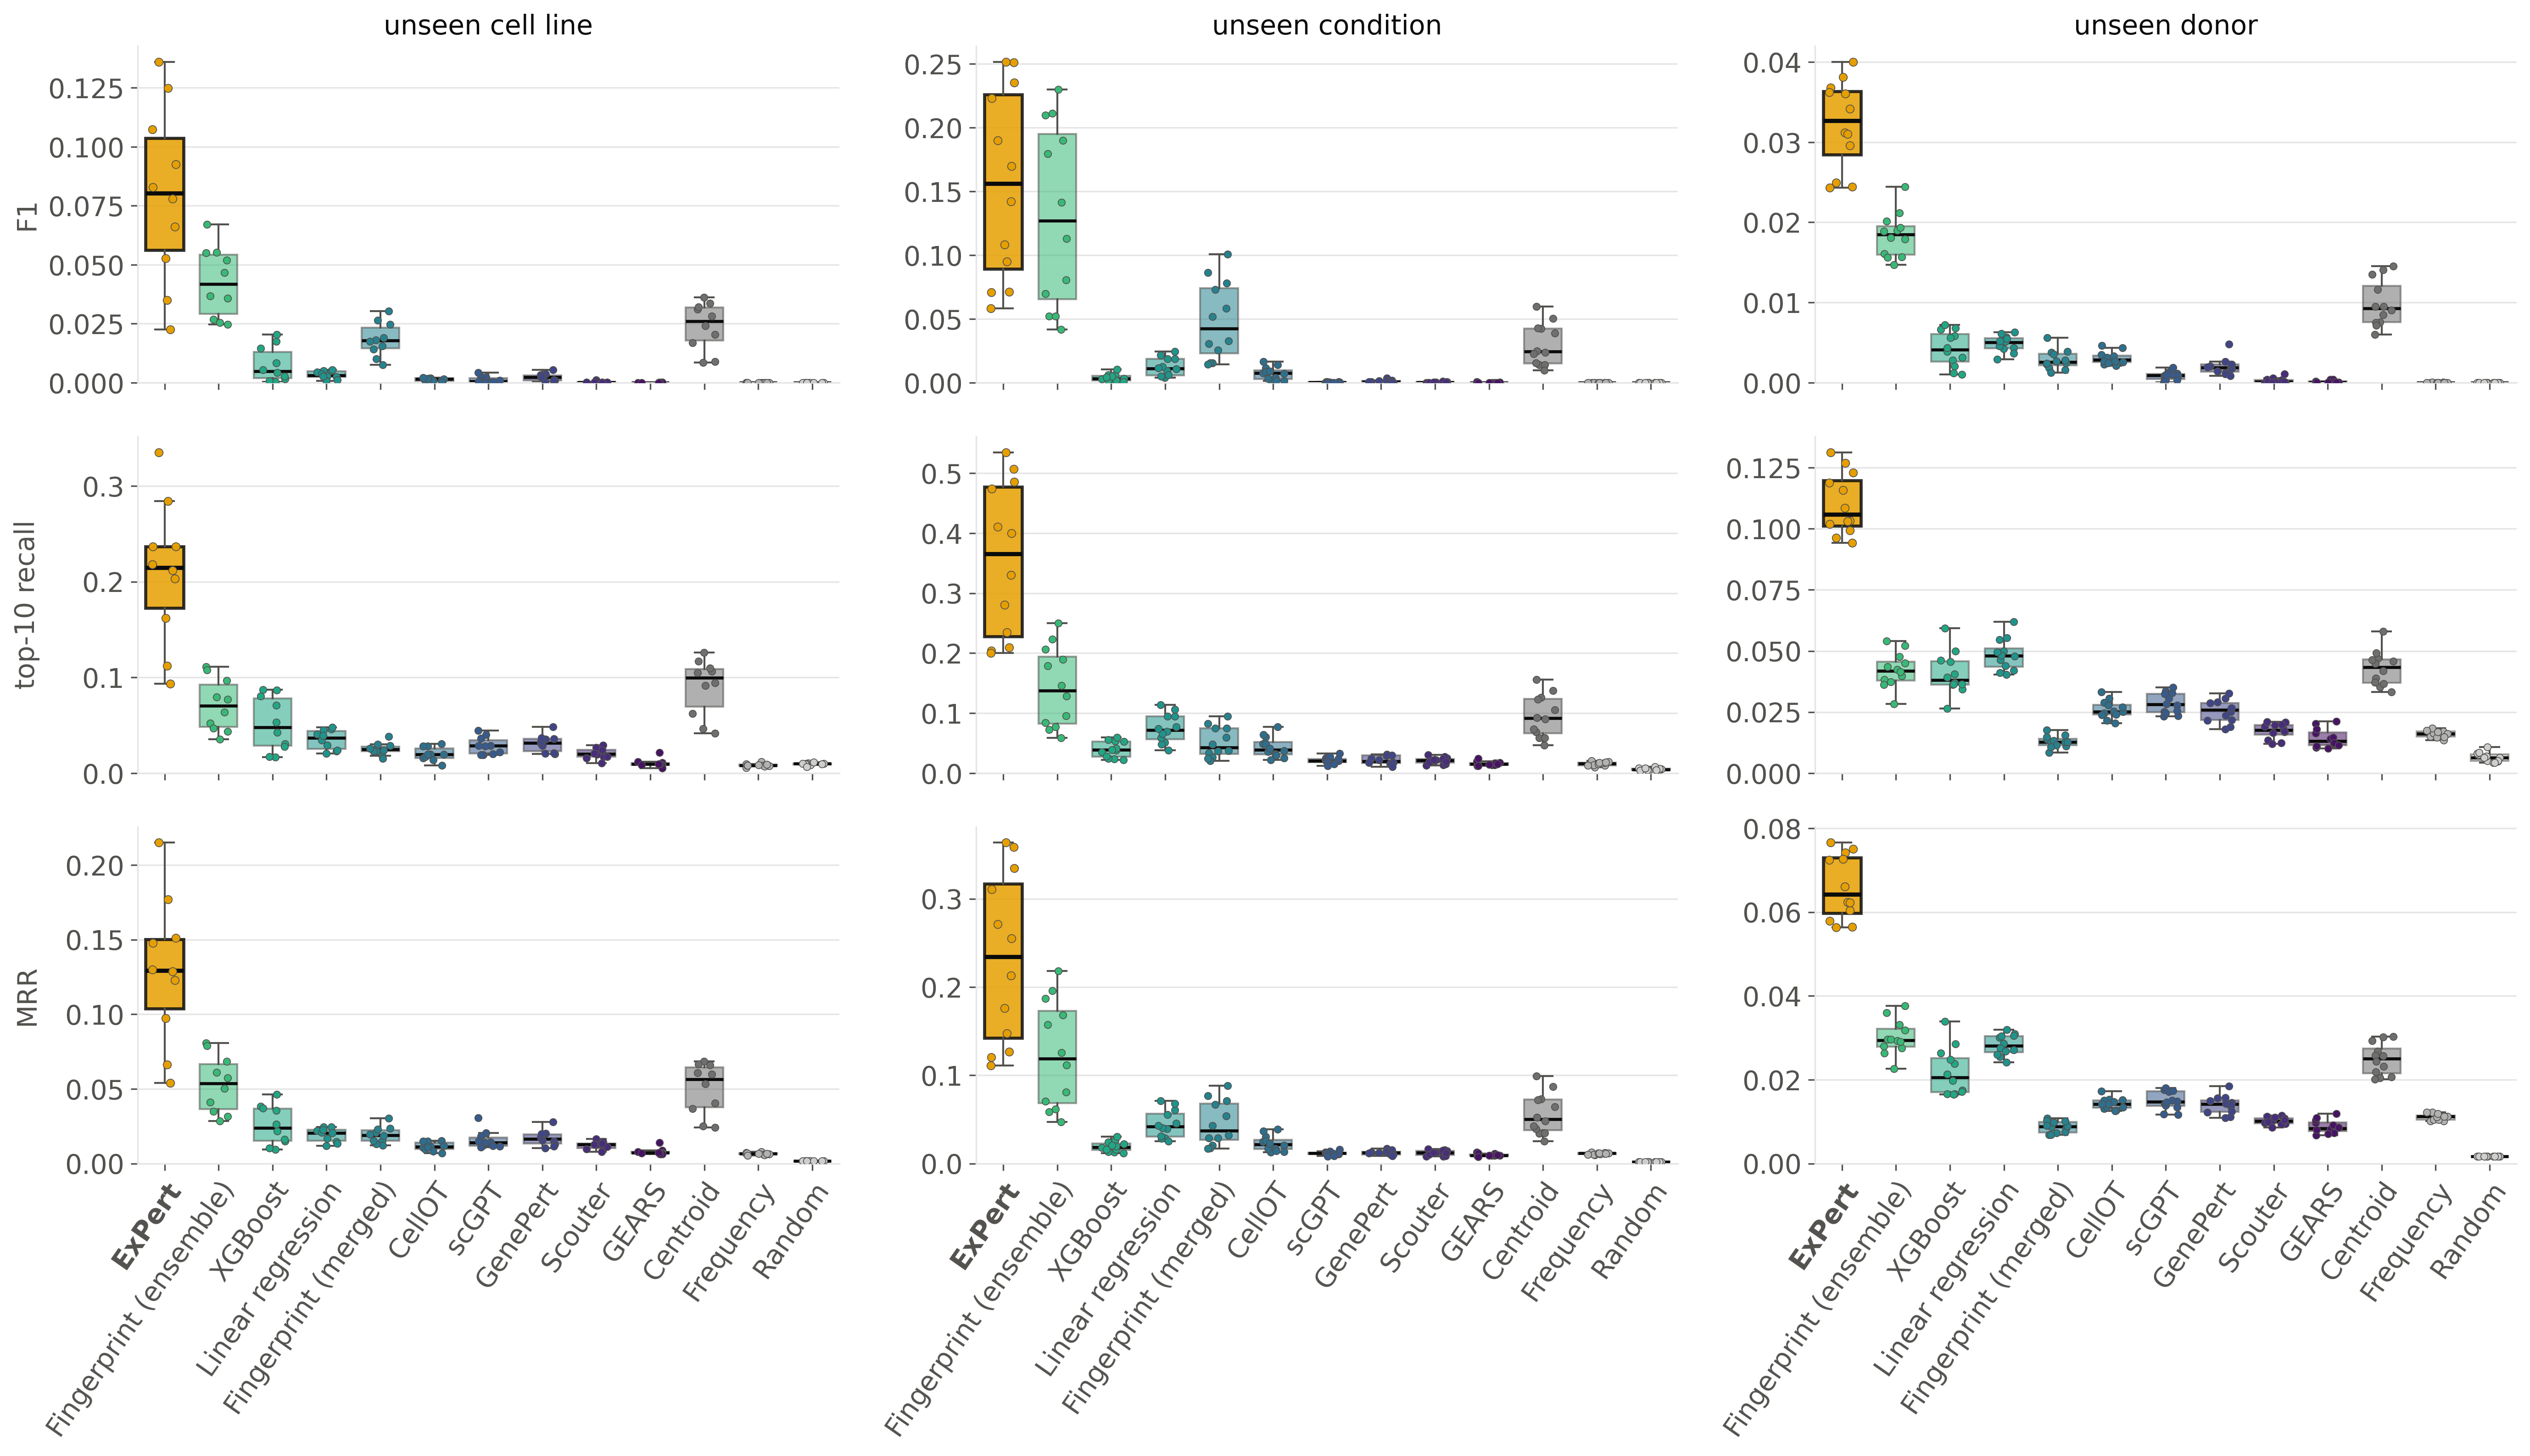

In [6]:
P2.panel_b(DATA, OUT, metrics, keep=F.SHIFTS, name='figS3d_ood_by_shift_cell',
           table='figS3d_ood_by_shift_cell.csv')
nb.show(OUT, 'figS3d_ood_by_shift_cell')

## E — effect-size threshold vs a random sample of the same number of cells (OOD)

  wrote figS3e_subsample_control.svg / .png


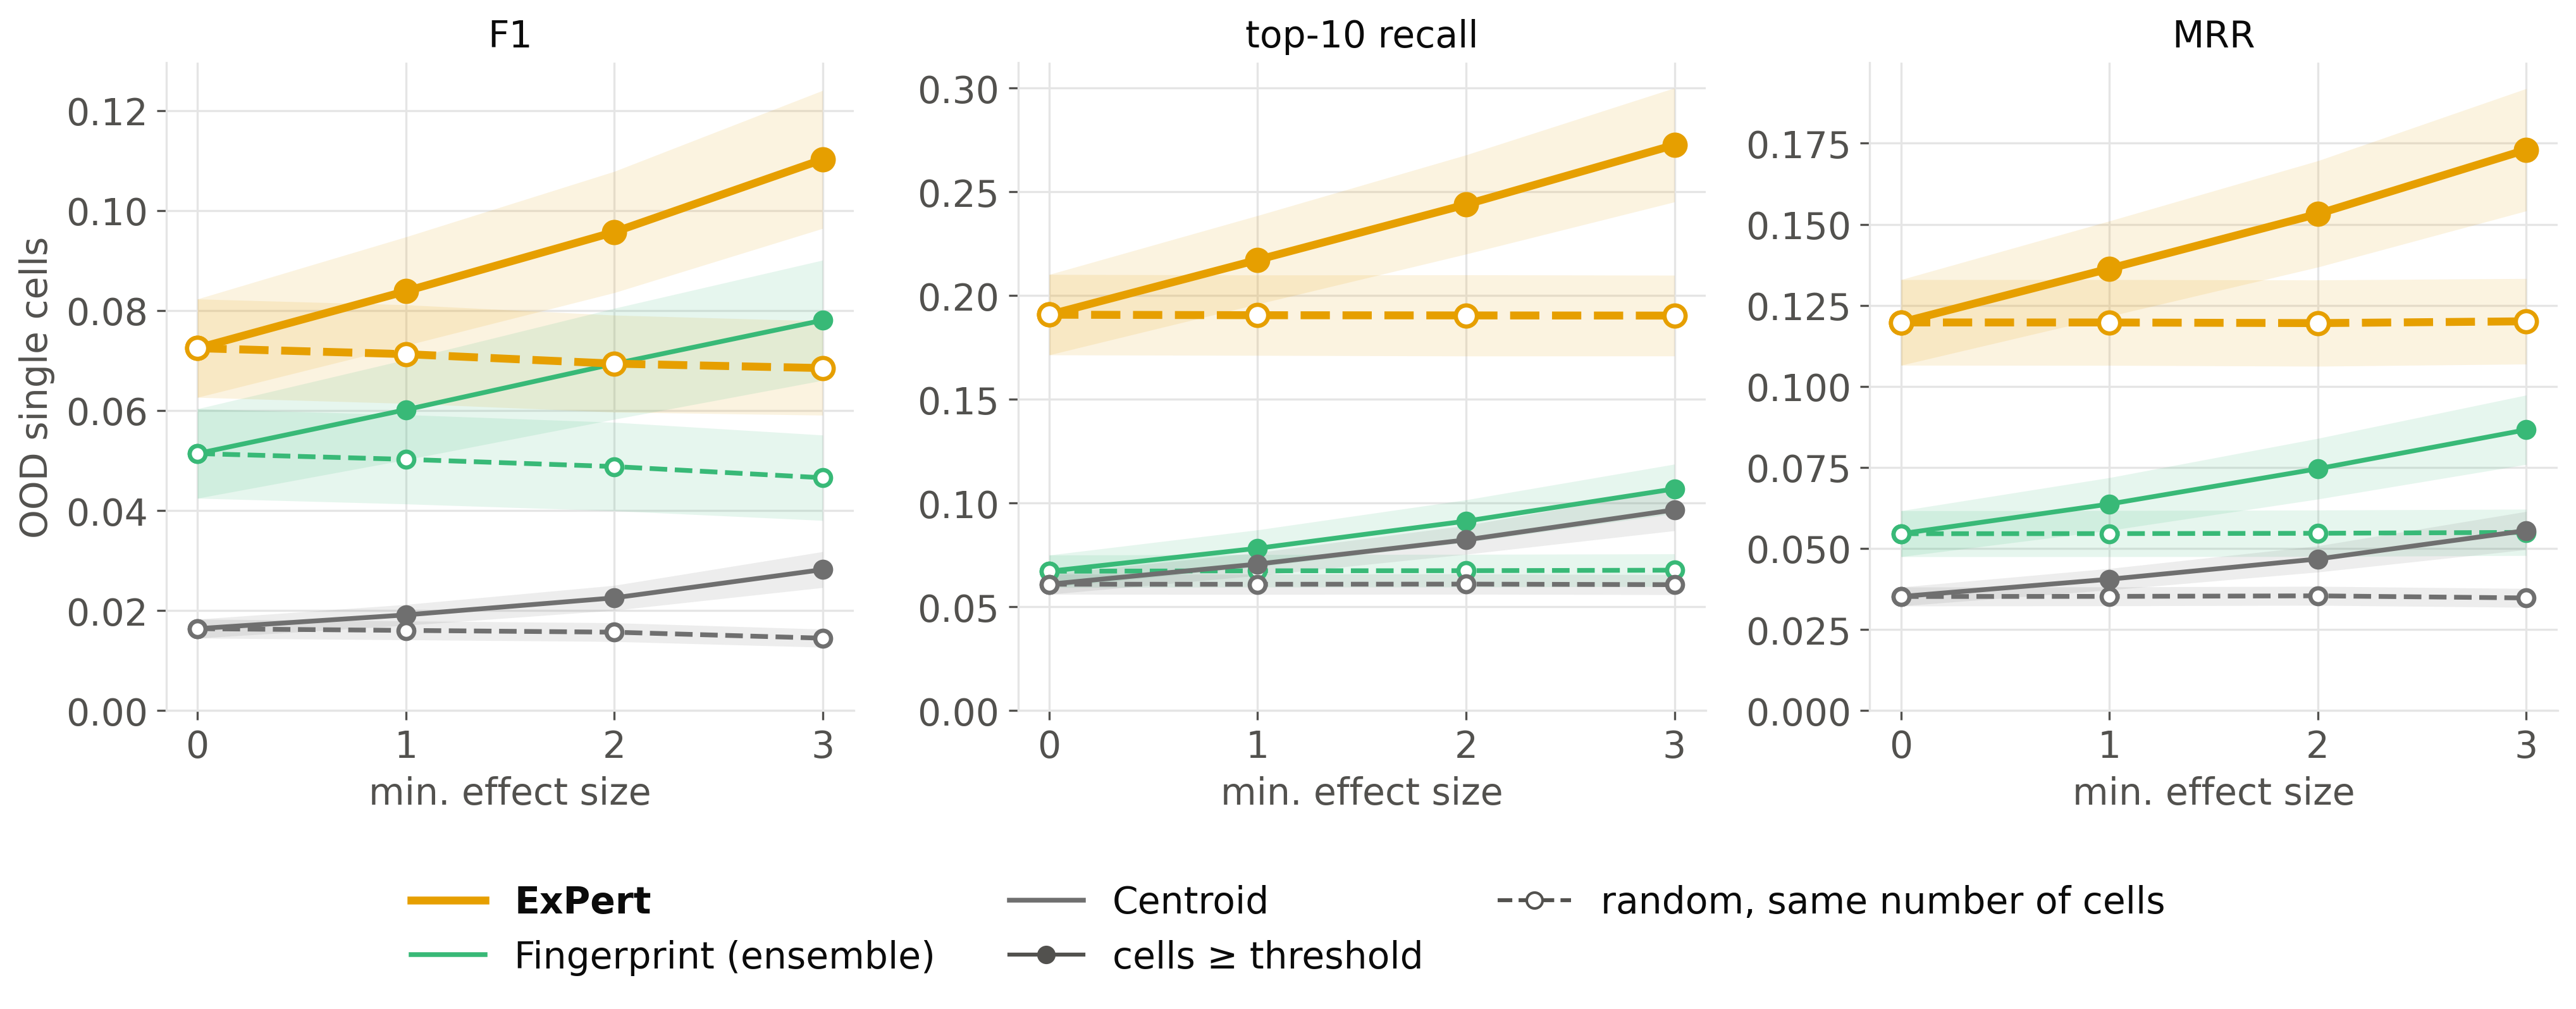

In [7]:
P.subsample(DATA, OUT)
nb.show(OUT, 'figS3e_subsample_control')